# Snapshot with JuMP: your first calculation

**Open source**: Julia + JuMP + HiGHS. No license needed.
The same tutorial with AMPL is [`01_snapshot_ampl.ipynb`](01_snapshot_ampl.ipynb).

---

This notebook walks you through, step by step:

1. **computing** the least-cost energy system of Quebec for a given year;
2. **reading** the results (cost, installed technologies, emissions);
3. **changing an assumption** and measuring its effect.

*Duration: about 15 minutes. No programming required: click in a cell and press* **Shift + Enter**.

## Before you start: the model in one minute

- The model chooses **which technologies to install and operate** to meet Quebec's energy demand (electricity, heat, transport, industry) at the **lowest total cost**.
- This notebook computes a **snapshot**: a single year (for example 2030). The full 2020 to 2050 pathway will be covered in a later tutorial.
- Units: costs in **M$CAD per year**, capacities in **GW**, energy in **GWh**, emissions in **ktCO2-eq**.

## 1. Setup

Run the cell below once.

> *Requirements: Python with the project installed (`pip install -e .` at the root of the repository) and `juliacall` (`pip install juliacall`).
> `juliacall` downloads and manages Julia by itself. The first calculation on a machine is slow (installation and compilation); the next ones are fast.*

In [1]:
import matplotlib.pyplot as plt
from shared.utils import load_snapshot, run_model

# Plots: the project's Sankey diagrams (same as the AMPL tutorial) and the energyscope library's other plots
from energyscope.plots import plot_eud, plot_resources_use
from shared.plotting import plot_sankey, plot_sankey_co2

## 2. Your first calculation

Pick a year among **2020, 2025, 2030, 2035, 2040, 2045, 2050**, then run the cell.

*Each calculation takes about one minute (a bit more for the very first one, while the calculation engine warms up).*

In [2]:
YEAR = 2050
results = run_model(load_snapshot(YEAR), backend="julia")

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


## 3. Reading the results

Everything the model computed is stored in `results`. To look at one quantity, write its name between brackets:

`results.variables["name"]`

### Total cost
The sum, for the year, of investments (spread over the equipment lifetime), operation and maintenance, and resources. In **M$CAD**.

In [3]:
results.variables["TotalCost"]

,TotalCost,Run
0,63405.36953,0


### Greenhouse gas emissions
In **ktCO2-eq** for the year.

In [4]:
results.variables["TotalGWP"]

,TotalGWP,Run
0,51024.033145,0


### Installed technologies
`F_Mult` is the installed capacity of each technology (in **GW**, or in the technology's own unit).

In [5]:
results.variables["F_Mult"]

,F_Mult,Run
index,,
PV_ROOF,0.000000,0
PV_GROUND,0.000000,0
TRAFO_ML,10.331909,0
AN_DIG_SI,0.000000,0
GEOTHERMAL,0.000000,0
...,...,...
CONTAINER_MEOH,1.864263,0
OIL_TANKER_MEOH,4.158038,0
BULK_CARRIER_BIOMEOH,0.000000,0


### What else can I look at?
`results.variables["..."]` works with any variable of the model. To see the complete list of names, run:

In [6]:
list(results.variables)

['F_Mult',
 'F_Mult_t',
 'Annual_Prod',
 'Annual_Res',
 'TotalCost',
 'TotalGWP',
 'C_inv',
 'C_maint',
 'C_op']

Some useful ones:

| Name | Meaning | Unit |
|---|---|---|
| `TotalCost` | total cost of the system | M$CAD |
| `TotalGWP` | total greenhouse gas emissions | ktCO2-eq |
| `F_Mult` | installed capacity of each technology | GW |
| `Annual_Prod` | energy produced over the year by each technology | GWh |
| `C_inv` | annualized investment cost of each technology | M$CAD |

### Graphs
The `energyscope` library draws the most common plots directly from `results`.

**Energy flows (Sankey diagram)**: how energy goes from resources, through technologies, to the end uses.

In [7]:
plot_sankey(results)

### Final energy demand and resources used

In [8]:
plot_eud(results)

In [9]:
plot_resources_use(results)

### Where the CO2 comes from and where it goes

In [10]:
plot_sankey_co2(results)   # where the CO2 comes from and where it goes

### Cleaner tables (optional)
The raw tables above contain every technology, even those that are not installed. The two small helpers below
give a cleaner view: `table(results, "name")` returns one variable as a simple list of numbers, and
`capacities(results)` keeps only the technologies that were actually built, largest first.
You do not need to understand the code: just run the cell.

In [11]:
def table(res, name):
    """One model variable as a pandas Series, e.g. table(results, "F_Mult")."""
    s = res.variables[name].drop(columns=["Run"], errors="ignore").iloc[:, 0].astype(float)
    return s.droplevel("year") if "year" in s.index.names else s


def capacities(res, top=12):
    """Installed capacities [GW] of the technologies that require an investment (largest first)."""
    cap, inv = table(res, "F_Mult"), table(res, "C_inv")
    cap = cap[(cap > 1e-6) & (inv.reindex(cap.index).fillna(0) > 1e-9)]
    return cap.sort_values(ascending=False).head(top)

In [12]:
cost = table(results, "TotalCost").sum()
print(f"Total system cost in {YEAR}: {cost:,.0f} M$CAD  ({cost / 1000:,.1f} G$CAD)")

Total system cost in 2050: 63,405 M$CAD  (63.4 G$CAD)


Installed capacities, in **GW**, of the technologies that require an investment:

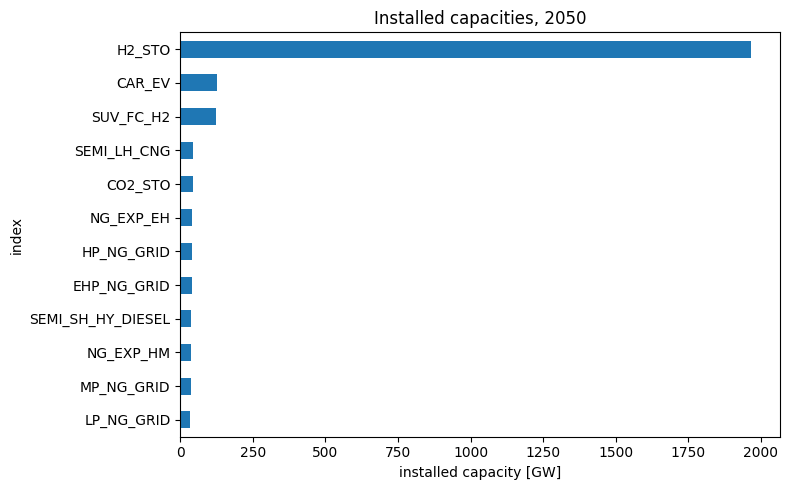

In [13]:
capacities(results).iloc[::-1].plot.barh(figsize=(8, 5))
plt.xlabel("installed capacity [GW]")
plt.title(f"Installed capacities, {YEAR}")
plt.tight_layout()

In [14]:
# The same data as a table
capacities(results, top=15)

index
H2_STO               1968.383050
CAR_EV                127.096708
SUV_FC_H2             121.733573
SEMI_LH_CNG            43.393563
CO2_STO                41.888145
NG_EXP_EH              39.131611
HP_NG_GRID             39.131611
EHP_NG_GRID            39.131611
SEMI_SH_HY_DIESEL      36.151513
NG_EXP_HM              35.872911
MP_NG_GRID             35.872911
LP_NG_GRID             32.484051
NG_EXP_ML              32.484051
DEC_BOILER_GAS         29.543624
HYDRO_DAM              26.357000
Name: F_Mult, dtype: float64

Energy produced over the year, in **GWh** (the 15 largest):

In [15]:
prod = table(results, "Annual_Prod")
prod[prod > 1].sort_values(ascending=False).head(15)

index
EHV_GRID          239241.716649
NG_EXP_EH         222469.257005
EHP_NG_GRID       222469.257005
HP_NG_GRID        222469.257005
TRAFO_EH          186306.422271
HV_GRID           186306.422271
MP_NG_GRID        177077.400294
NG_EXP_HM         177077.400294
HYDRO_DAM         127918.533528
LP_NG_GRID        123242.551568
NG_EXP_ML         123242.551568
DEC_BOILER_GAS    112086.747911
MV_GRID           101115.890720
TRAFO_HM          101115.890720
TRAFO_ML           73713.664655
Name: Annual_Prod, dtype: float64

## 4. Changing an assumption

To test a "what if...?", you write your changes in a small text file, **`my_changes.dat`**, in the folder `example_files` next to this notebook.
You do not need to change anything else: the standard data files are never modified.

Open `my_changes.dat` in any text editor. It contains ready-to-use examples. Example 1 is switched on; the others are switched off by a `#` at the start of the line:

| Example | What it does |
|---|---|
| 1 | natural gas becomes 50 % more expensive |
| 2 | onshore wind becomes 30 % cheaper |
| 3 | no nuclear capacity at all |
| 4 | one precise value for one precise year |
| 5 | limit on the combined capacity of several technologies (a `sum`) |

To switch an example on, remove the `#` at the start of its `for {...` or `let ...` line (not the title line), change the number if you wish, and **save the file**.

If a name is misspelled (a parameter or a technology), the calculation stops with a message that gives the line and suggests the closest name.

The file as it is now:

In [16]:
print(open("example_files/my_changes.dat", encoding="utf8").read())

# ============================================================================
#  My changes to the EnergyScope-Quebec data
# ============================================================================
#  How it works
#    1. Remove the "#" at the start of a line to turn it on (a line that starts with "#" is ignored).
#    2. Change the number, save this file.
#    3. In the notebook, run the cell that uses this file.
#
#  Everything you write here is applied on top of the standard data. The standard
#  data files are never modified, so you can always come back by putting the "#" back.
#
#  Reading a line:   let  <parameter>[ <year>, <technology or resource> ]  :=  <new value> ;
#     * "y" stands for the year of the calculation, so these lines work for any year.
#     * To change a value relative to its current one, use the parameter itself:
#          c_inv[y,'WIND_ONSHORE'] * 0.7      means  "30 % cheaper than today"
#     * Every line ends with a semicolon ( ; )
#     * Names must

### Run with your changes
**Example 1** (natural gas +50 %) is already switched on in `my_changes.dat`. Run the next cell.

In [17]:
model = load_snapshot(YEAR)
model.files.append(("mod", "example_files/my_changes.dat"))   # applied on top of the standard data
mine = run_model(model, backend="julia")

cost_mine = table(mine, "TotalCost").sum()
print(f"Base: {cost:,.0f} M$CAD   With my changes: {cost_mine:,.0f} M$CAD   ({100 * (cost_mine / cost - 1):+.2f} %)")

Base: 63,405 M$CAD   With my changes: 65,668 M$CAD   (+3.57 %)


Does the **choice of technologies** change? And the resources used?

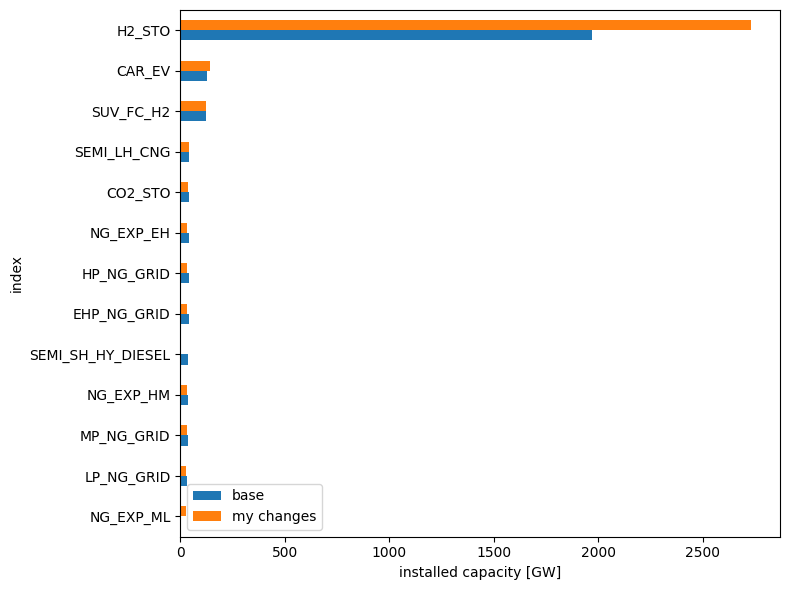

In [18]:
import pandas as pd
pd.concat([capacities(results).rename("base"), capacities(mine).rename("my changes")], axis=1).fillna(0).iloc[::-1].plot.barh(figsize=(8, 6))
plt.xlabel("installed capacity [GW]")
plt.tight_layout()

In [19]:
plot_resources_use(mine)   # resources used with your changes

### Try other changes
Edit `my_changes.dat` again (for example put the `#` back on Example 1 and remove it on Example 2), save, and run the cell
**"Run with your changes"** once more. Compare with the base each time.

You can write as many lines as you like in the file, hundreds if needed: it is the same file whether you change one value or a thousand.

## 5. Finding the name of a parameter or a technology

**Most useful parameters** (the key is `(year, technology)` unless stated otherwise):

| Parameter | Meaning | Unit |
|---|---|---|
| `c_inv` | investment cost | M$CAD per GW |
| `c_maint` | operation and maintenance cost | M$CAD per GW per year |
| `lifetime` | lifetime | years |
| `f_max`, `f_min` | maximum, minimum installable capacity | GW |
| `c_op` | cost of a resource, key `(year, resource, month)` | M$CAD per GWh |
| `avail` | available quantity of a resource, key `(year, resource)` | GWh per year |

**Technology names:**

In [20]:
technologies = sorted(set(table(results, "F_Mult").index))
print(len(technologies), "technologies. The first 40:")
print(", ".join(technologies[:40]))

690 technologies. The first 40:
AFC, ALKALINE_ELECTROLYSIS, AL_MAKING, AL_MAKING_HR, AN_DIG, AN_DIG_SI, ATR, ATR_CCS, BATTERY, BIOETHANOL_TO_BIOJETFUELS, BIOGAS_ATR, BIOGAS_ATR_CCS, BIOGAS_BIOMETHANE, BIOGAS_SMR, BIOGAS_SMR_CCS, BIOMASS_GAS_EF_H2, BIOMASS_GAS_EF_H2_CCS, BIOMASS_GAS_FB_H2, BIOMASS_GAS_FB_H2_CCS, BIOMETHANE_TO_BIOMETHANOL, BIOMETHANOL_CARBONYLATION, BIOMETHANOL_FT, BIOMETHANOL_TO_AROMATICS, BIOMETHANOL_TO_OLEFINS, BULK_CARRIER, BULK_CARRIER_BIO, BULK_CARRIER_BIOMEOH, BULK_CARRIER_BIOMEOH_ELD, BULK_CARRIER_BIO_ELD, BULK_CARRIER_ELD, BULK_CARRIER_MEOH, BULK_CARRIER_MEOH_ELD, BUS_BIODIESEL_B100, BUS_BIODIESEL_B100_SD, BUS_BIODIESEL_B20, BUS_BIODIESEL_B20_SD, BUS_CNG, BUS_CNG_SD, BUS_CSNG, BUS_CSNG_SD


## 6. Good to know

- The Sankey diagrams are the project's own (`shared.plotting`, same as the AMPL tutorial); the other plots come from the `energyscope` library (`energyscope.plots`).
- This notebook computes **one year at a time**. The 2020 to 2050 pathway is in [`04_pathway_jump_opensource.ipynb`](04_pathway_jump_opensource.ipynb).
- When several combinations of technologies cost almost the same, the model may pick one rather than another; compare mainly the **costs** and the **overall trends**.
- Questions or problems: see `tutorials/README.md`.